-Martina Yed- Análisis y Procesamiento de Señales

TS1: Síntesis y operaciones de señales

EJERCICIO 1

La Transformada de Fourier de Tiempo Discreto (DTFT) es la herramienta analítica fundamental para describir la respuesta espectral de cualquier estímulo o sistema. Sin embargo, como el análisis numérico computacional exige trabajar con vectores finitos, aplicamos la Transformada Discreta de Fourier (DFT) para evaluar estas secuencias exactamente en un número discreto de muestras.

--Señal sinusoidal de 2 KHz que tenga al menos 10 puntos por período--

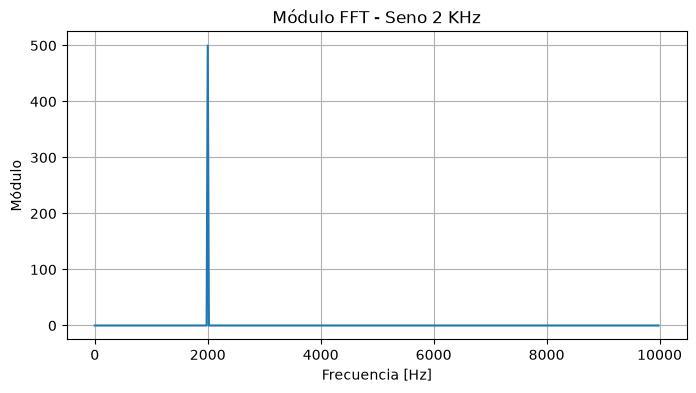

In [2]:
import numpy as np
import matplotlib.pyplot as plt
fs = 20000  # 10 puntos por período de 2000 Hz
N = 1000
f0 = 2000

tt = np.arange(0, N/fs, 1/fs)
freq = np.arange(N//2) * (fs / N)

# Síntesis
x_n = 1 * np.sin(2 * np.pi * f0 * tt)

# Transformada y Módulo
fft_x_n = np.fft.fft(x_n)
mod_x_n = np.abs(fft_x_n[:N//2])

plt.figure(figsize=(8, 4))
plt.plot(freq, mod_x_n)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo')
plt.title('Módulo FFT - Seno 2 KHz')
plt.grid()
plt.show()

Un solo período de esta señal dura T = 1/2000s. En ese tiempo necesitamos que haya 10 muestras, la frecuencia de muestreo debe ser como mínimo 10 \2000 = 20000 Hz.Entocnes usamos f_s = 20000 dejando la variable N = 1000.

En el gráfico se ve un único pico perfectamente definido sobre la marca de 2000 Hz. Esto ocurre porque la representación en el dominio de la frecuencia de una sinusoide pura consiste exclusivamente en impulsos en su frecuencia fundamental.
El eje vertical marca un pico exacto de 500. Cuando la frecuencia de una sinusoide es un múltiplo entero de la resolución frecuencial de la transformada, la Transformada Discreta de Fourier (DFT) concentra la energía en dos impulsos no nulos con una magnitud de N/2 por cada componente exponencial. Como tenemos N=1000 muestras y la amplitud de la señal original es 1 V, el módulo teórico esperado es exactamente 1000/2 = 500.  

---Misma señal con 2 W de potencia media y desfasada en π/2---

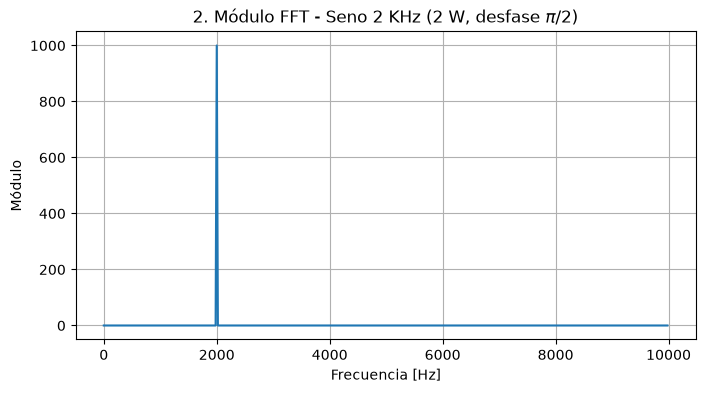

In [6]:
import numpy as np
import matplotlib.pyplot as plt
A = 2
f0 = 2000
fase = np.pi / 2

x_n = A * np.sin(2 * np.pi * f0 * tt + fase)

fft_x_n = np.fft.fft(x_n)
mod_x_n = np.abs(fft_x_n[:N//2])

plt.figure(figsize=(8, 4))
plt.plot(freq, mod_x_n)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo')
plt.title('2. Módulo FFT - Seno 2 KHz (2 W, desfase $\\pi/2$)')
plt.grid()
plt.show()

Al igual que en tu primera señal, la energía se concentra en un único "pico" sobre la marca de 2000 Hz. Esto sucede porque lo mismo que explique antes.
La potencia media de una onda senoidal pura de amplitud A es P = A^2 / 2. Para que la potencia sea de 2 W, necesitamos que A^2 = 4, es decir, una amplitud de 2V.La Transformada Discreta de Fourier concentra la energía de esa amplitud en un impulso cuya magnitud se escala por un factor de N/2. Como tu vector tiene N=1000 muestras, el cálculo matemático para el eje vertical es exacto: 2x500 = 1000.

Cuando calculamos el módulo usando np.abs(), estamos midiendo únicamente la potencia/energía en 2000Hz. Al tomar el valor absoluto, eliminamos por completo la noción de tiempo o posición. 
Por eso decimos que el desfasaje es "invisible" en este gráfico: mover la onda hacia la izquierda o hacia la derecha en el tiempo no cambia cuánta energía total tiene, solo cambia cuándo ocurre.

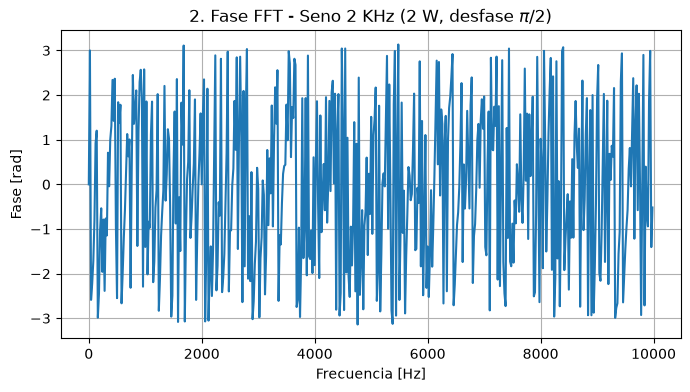

In [10]:
import numpy as np
import matplotlib.pyplot as plt
A = 2
f0 = 2000
fase = np.pi / 2

x_n = A * np.sin(2 * np.pi * f0 * tt + fase)

fft_x_n = np.fft.fft(x_n)
fase_x_n = np.angle(fft_x_n[:N//2])

plt.figure(figsize=(8, 4))
plt.plot(freq, fase_x_n)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Fase [rad]')
plt.title('2. Fase FFT - Seno 2 KHz (2 W, desfase $\\pi/2$)')
plt.grid()
plt.show()

En este segundo gráfico donde dibujamos la fase, lo que hacemos es usar np.angle() para extraer la fase de cada componente. Si miramos todo el espectro, la fase hace saltos raros porque en las frecuencias donde no hay señal (donde el módulo es cero o solo hay ruido de redondeo) la fase no tiene sentido físico.Pero si miramos exactamente sobre la marca de los 2000 Hz (donde está nuestro pico de energía), la curva se detiene y marca un valor constante de pi/2radianes (1.57 rad).

--Una secuencia aleatoria de ruido uniformemente distribuido con DC (valor medio) 0V y varianza 0.1 W.--

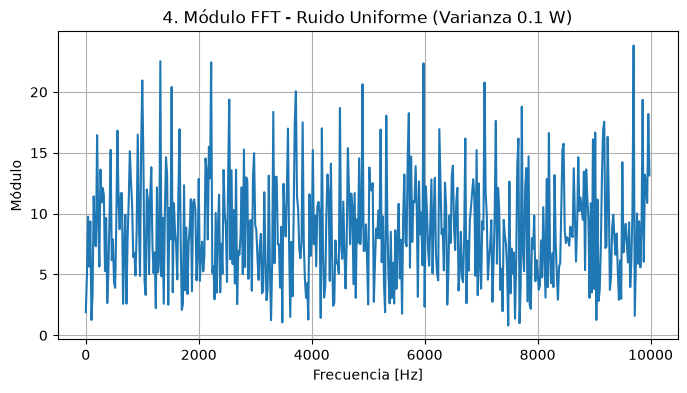

In [11]:
import numpy as np
import matplotlib.pyplot as plt
N = 1000
fs = 20000 
freq = np.arange(N//2) * (fs / N)
a = np.sqrt(0.3)
ruido_uniforme = np.random.uniform(-a, a, N)

fft_ruido = np.fft.fft(ruido_uniforme)
mod_ruido = np.abs(fft_ruido[:N//2])

plt.figure(figsize=(8, 4))
plt.plot(freq, mod_ruido)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo')
plt.title('4. Módulo FFT - Ruido Uniforme (Varianza 0.1 W)')
plt.grid()
plt.show()

Ruido uniformemente distribuido en lugar de dibujar una onda suave, la función np.random.uniform escupe 1000 valores numéricos totalmente al azar. DC (valor medio) 0V Como los números se eligen al azar entre un límite negativo y uno positivo idéntico (-a y a), se compensan entre sí. El promedio matemático de toda la señal es cero.
Para el cálculo de la varianza: La consigna nos pide una varianza de $0.1$. En estadística, la varianza de un ruido uniforme entre $-a$ y $a$ se calcula con la siguiente fórmula:

$$V = \frac{(2a)^2}{12} = \frac{a^2}{3}$$

Si necesitás que $V = 0.1$, al despejar la ecuación te queda $a^2 = 0.3$, por lo que el límite debe ser $a = \sqrt{0.3}$.

Lo que podemos decir del grafico es que cuando aplicámos la Transformada Rápida de Fourier (FFT) a este ruido para ver qué frecuencias lo componen, la herramienta no encuentra ningún patrón limpio. Como el ruido es aleatorio, está compuesto por una mezcla impredecible de todas las frecuencias al mismo tiempo. Por esto mismo, el dibujo ya no muestra una sola línea recta ascendente como en los graficos anteriores. Lo que vemos es un montón de picos desordenados a lo largo de todo el eje de frecuencias. El gráfico nos demuestra que la energía del ruido está repartida de forma aleatoria por todo el espectro, sin que ninguna frecuencia logre dominar sobre el resto.

--Un pulso rectangular de la misma frecuencia, 1 W de potencia y ciclo de actividad del 50%--

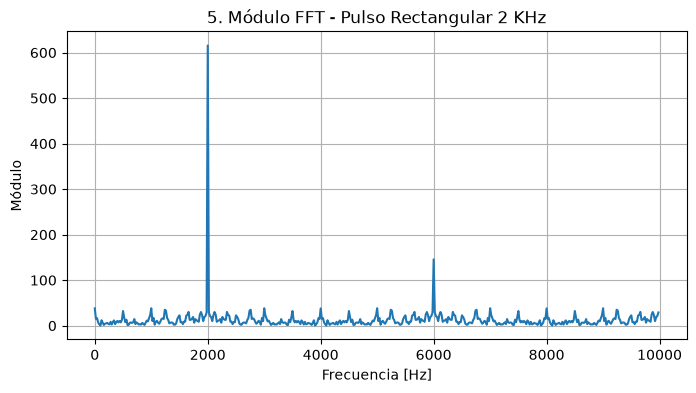

In [13]:
from scipy import signal


pulso_rect = 1 * signal.square(2 * np.pi * 2000 * tt, duty=0.5)

fft_pulso = np.fft.fft(pulso_rect)
mod_pulso = np.abs(fft_pulso[:N//2])

plt.figure(figsize=(8, 4))
plt.plot(freq, mod_pulso)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo')
plt.title('5. Módulo FFT - Pulso Rectangular 2 KHz')
plt.grid()
plt.show()

La función que usamos sacada de (scipy.signal apartado Waveforms) signal.square(...): Esta función de la librería SciPy es la que dibuja los escalones. Obliga a la señal a saltar de golpe de un valor positivo a uno negativo, sin pasar por los valores intermedios. El ciclo de actividad. Significa que la onda es perfectamente simétrica: pasa el 50% del tiempo en su valor máximo y el otro 50% en su valor mínimo.

El pico principal en 2000 Hz: Es la frecuencia fundamental. Como pusimos a la señal que repita su ciclo completo 2000 veces por segundo, la mayor parte de la energía está concentrada ahí.
El segundo pico en 6000 Hz: Para que una onda tenga esquinas "cuadradas" en lugar de curvas suaves, la naturaleza matemática necesita sumar frecuencias más agudas. A estos componentes ocultos se los llama armónicos. Por regla física, una onda cuadrada perfecta del 50% se construye sumando su frecuencia base con sus múltiplos impares (2000 Hz, luego 6000 Hz, luego 10000 Hz, etc.). El gráfico descubrió y separó ese armónico de 6000 Hz que estaba escondido armando los escalones.

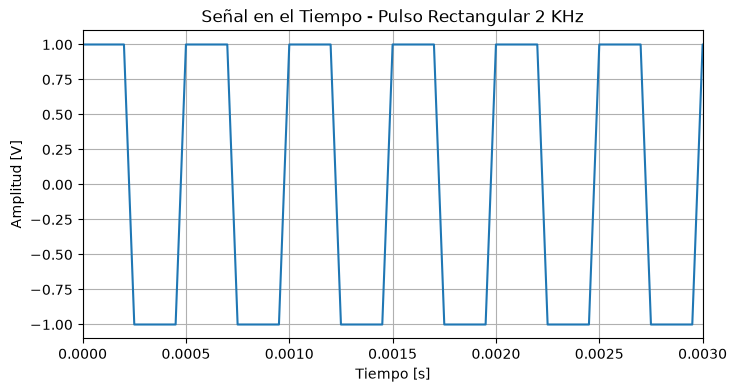

In [14]:
from scipy import signal
pulso_rect = 1 * signal.square(2 * np.pi * 2000 * tt, duty=0.5)

fft_pulso = np.fft.fft(pulso_rect)
mod_pulso = np.abs(fft_pulso[:N//2])
plt.figure(figsize=(8, 4))
plt.plot(tt, pulso_rect)
plt.xlim(0, 0.003) # Muestra solo los primeros 3 milisegundos (6 ciclos)
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud [V]')
plt.title('Señal en el Tiempo - Pulso Rectangular 2 KHz')
plt.grid()
plt.show()

Este nuevo gráfico representa lo que veríamos al conectar un osciloscopio real. Nos muestra la forma de onda "cruda", los saltos bruscos y cómo se comporta la amplitud a medida que avanzan los milisegundos. 
El gráfico tambie nos sirve para justificar visualmente lo que pasa en la frecuencia. Al ver los saltos totalmente verticales entre 1 y -1 en el tiempo.
El gráfico temporal explica por qué el espectro de frecuencias se ve así. Los saltos de golpe que da la onda cuadrada no se pueden generar con una sola frecuencia base. El pico en 6000 Hz y las variaciones de fondo que detecta la FFT son justamente esas frecuencias adicionales (los armónicos) que se suman para lograr que los bordes de la señal queden rectos. En resumen: cuanto más rápido y brusco cambia la señal en el tiempo, más frecuencias agudas van a saltar en el análisis de la FFT.

--BONUS--

--Señal diente de sierra--

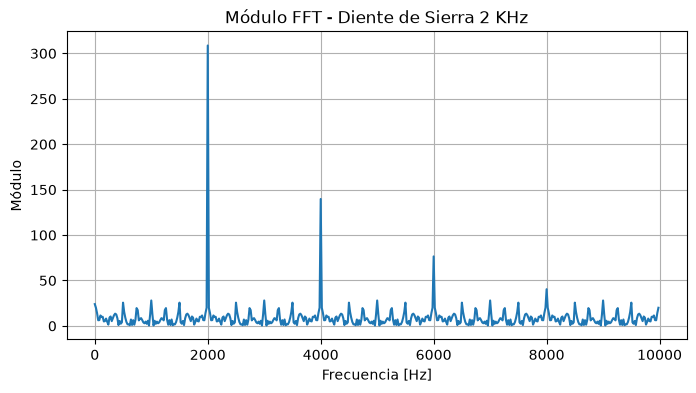

In [16]:
# 2 kHz, amplitud 1 V
tt = np.arange(0, N/fs, 1/fs)
f0 = 2000

# scipy.signal
s_saw = signal.sawtooth(2 * np.pi * f0 * tt)

fft_saw = np.fft.fft(s_saw)
mod_saw = np.abs(fft_saw[:N//2])

plt.figure(figsize=(8, 4))
plt.plot(freq, mod_saw)
plt.xlabel('Frecuencia [Hz]')
plt.ylabel('Módulo')
plt.title('Módulo FFT - Diente de Sierra 2 KHz')
plt.grid()
plt.show()

El diente de sierra es como una rampa la amplitud sube de a poco y de repente cae a cero. A diferencia de la onda cuadrada que solo usaba frecuencias impares, para lograr esta caída tan brusca la FFT necesita usar todos los armónicos enteros (2000 Hz, 4000 Hz, 6000 Hz, 8000 Hz...). Básicamente, el espectro nos muestra que para dibujar ese serrucho perfecto, la matemática necesita meter en la mezcla absolutamente todas las frecuencias múltiples, cada vez con un poquito menos de fuerza.

--Averiguar cómo se podría medir la potencia mediante la transformada de Fourier (Ver Teorema de Parseval)--

El Teorema de Parseval establece el principio de conservación de la energía: la energía total calculada en el dominio del tiempo es exactamente igual a la calculada en el dominio de la frecuencia. La forma de mirar la señal cambia, pero la cantidad de energía física contenida se mantiene intacta.

En el dominio del tiempo, la potencia media se calcula como el promedio de las muestras al cuadrado:

$$P_{\text{tiempo}} = \frac{1}{N} \sum_{n=0}^{N-1} |x[n]|^2$$

En el dominio de la frecuencia (FFT), la potencia total se calcula sumando los módulos de todos los puntos de la FFT al cuadrado, divididos por $N^2$:

$$P_{\text{frecuencia}} = \frac{1}{N^2} \sum_{k=0}^{N-1} |X[k]|^2$$

In [17]:
# Potencia en el tiempo
p_tiempo = np.mean(x_n**2)

# Potencia en la frecuencia
p_frecuencia = np.sum(np.abs(np.fft.fft(x_n))**2) / (N**2)

print(f"Potencia en tiempo: {p_tiempo:.4f} W")
print(f"Potencia en frecuencia (Parseval): {p_frecuencia:.4f} W")

Potencia en tiempo: 2.0000 W
Potencia en frecuencia (Parseval): 2.0000 W


Esto esta confirmando que la potencia de cada armónico en el espectro suma exactamente la potencia total medida en la señal temporal.

EJERCICIO 2

In [2]:
from IPython.display import IFrame

# Esto mostrará el PDF incrustado debajo de la celda
IFrame("TS1_Martina_Yed_260830_205040.pdf", width=1000, height=800)